# Clusteranalyse

## Präambel

Wir laden alle Pakete und Module, die wir im Folgenden benötigen.

In [1]:
# Paket für Daten
import kagglehub

# Visualisierung und Datentransformation
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Pakete für Clusteranalyse und Feature Selection
from sklearn import preprocessing
from sklearn.cluster import Birch, KMeans
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import silhouette_samples, silhouette_score

# Pakete für Landkarten
import geopandas # Achte auf die Version: https://stackoverflow.com/questions/5226311/installing-specific-package-version-with-pip
from pyproj import Transformer

## Daten

Whisky-Datensatz von https://www.kaggle.com/datasets/koki25ando/scotch-whisky-dataset

In [2]:
path = kagglehub.dataset_download("koki25ando/scotch-whisky-dataset") # Pfad zum heruntergeladenen Datensatz

# Lies die Daten ein
df = pd.read_csv(path + '/whisky.csv')

# Erster Blick auf den Datensatz
df

100%|██████████| 2.59k/2.59k [00:00<00:00, 1.43MB/s]

Extracting files...


,RowID,Distillery,Body,Sweetness,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Fruity,Floral,Postcode,Latitude,Longitude
0,1,Aberfeldy,2,2,2,0,0,2,1,2,2,2,2,2,\tPH15 2EB,286580,749680
1,2,Aberlour,3,3,1,0,0,4,3,2,2,3,3,2,\tAB38 9PJ,326340,842570
2,3,AnCnoc,1,3,2,0,0,2,0,0,2,2,3,2,\tAB5 5LI,352960,839320
3,4,Ardbeg,4,1,4,4,0,0,2,0,1,2,1,0,\tPA42 7EB,141560,646220
4,5,Ardmore,2,2,2,0,0,1,1,1,2,3,1,1,\tAB54 4NH,355350,829140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,82,Tobermory,1,1,1,0,0,1,0,0,1,2,2,2,PA75 6NR,150450,755070
82,83,Tomatin,2,3,2,0,0,2,2,1,1,2,0,1,IV13 7YT,279120,829630
83,84,Tomintoul,0,3,1,0,0,2,2,1,1,2,1,2,AB37 9AQ,315100,825560
84,85,Tormore,2,2,1,0,0,1,0,1,2,1,0,0,PH26 3LR,315180,834960


Der Datensatz enthält die Koordinaten der einzelnen Destillerien. Das könnte man sich auf einer Karte ansehen...

## Exkurs A: Landkarten in Python

Das Paket `geopandas` bietet einen Rahmen für die Arbeit mit Geodaten. Das Modul `Transformer` aus dem Paket `pyproj` wird verwendet, um Koordinatensysteme von einem Standard in einen anderen zu konvertieren.

Zunächst laden wir eine Karte von UK.

In [3]:
# https://simplemaps.com/gis/country/gb
file = open("gb.json") # 4326-projection
ctry = geopandas.read_file(file)
ctry

,source,id,name,geometry
0,https://simplemaps.com,GBDRY,Derry,"POLYGON ((-7.41576 54.94437, -7.40866 54.95112..."
1,https://simplemaps.com,GBSTB,Strabane,"POLYGON ((-7.41576 54.94437, -7.41474 54.94373..."
2,https://simplemaps.com,GBFER,Fermanagh,"POLYGON ((-7.70795 54.60476, -7.69338 54.60075..."
3,https://simplemaps.com,GBDGN,Dungannon,"POLYGON ((-7.18947 54.33569, -7.18971 54.33604..."
4,https://simplemaps.com,GBARM,Armagh,"POLYGON ((-6.87001 54.326, -6.86743 54.3279, -..."
...,...,...,...,...
227,https://simplemaps.com,GBBIR,Birmingham,"POLYGON ((-1.85559 52.5755, -1.83169 52.58775,..."
228,https://simplemaps.com,GBSAW,Sandwell,"POLYGON ((-1.90281 52.54676, -1.91466 52.5278,..."
229,https://simplemaps.com,GBDUD,Dudley,"POLYGON ((-2.15387 52.42295, -2.15893 52.47742..."
230,https://simplemaps.com,GBWLL,Walsall,"POLYGON ((-2.05088 52.61743, -2.02589 52.61607..."


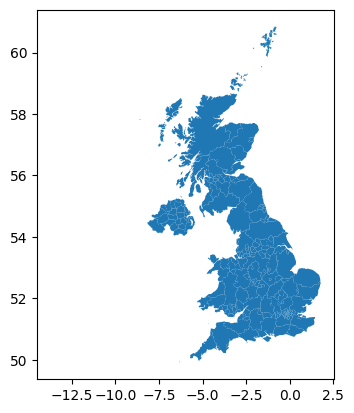

In [4]:
ctry.plot()
plt.show()

Dann legen wir unsere Daten über die Karte...

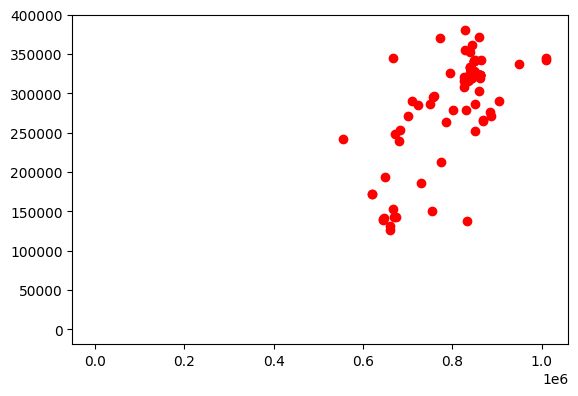

In [5]:
ctry.plot()
plt.scatter(x = df[['Longitude']], y = df[['Latitude']], marker='o', c = "red")
plt.show()

Wir müssen die Koordinatensysteme in ein einheitliches Format bringen. Dazu werden die Daten im Whisky-Datensatz transformiert:

In [7]:
coords = df[['Latitude', 'Longitude']]
coords_new = []

# Stelle den Transformer ein
transformer = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy=True) # always_xy behält unabhängig vom Koordinatensystem die Reihenfolge Längengrad, Breitengrad (x, y) bei

# Führe die Transformation für jede Zeile aus
for i in range(len(coords)):
    coord_i = transformer.transform(coords.iloc[i][0], coords.iloc[i][1])
    coord_i = pd.DataFrame({'Longitude': [coord_i[0]], 'Latitude': [coord_i[1]]})
    coords_new.append(coord_i)

# Wandle die Liste in einen einzigen Data Frame um
coords_new = pd.concat(coords_new)

# Setze den Index neu
coords_new = coords_new.reset_index()

# Zeige Ergebnis an
coords_new

/run/user/1000/app/org.jupyter.JupyterLab/ipykernel_439/4179123342.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coord_i = transformer.transform(coords.iloc[i][0], coords.iloc[i][1])


,index,Longitude,Latitude
0,0,-3.850199,56.625191
1,0,-3.229644,57.467395
2,0,-2.785295,57.441751
3,0,-6.108503,55.640607
4,0,-2.743628,57.350557
...,...,...,...
81,0,-6.069530,56.620806
82,0,-4.010031,57.341101
83,0,-3.411083,57.312680
84,0,-3.412996,57.397107


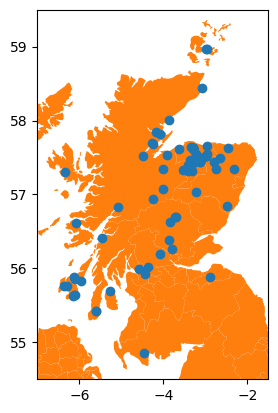

In [8]:
# Plotte Landkarte von UK
ctry.plot(color = "tab:orange")

# Füge Punkte hinzu
plt.scatter(x = coords_new[['Longitude']], y = coords_new[['Latitude']], marker='o', c = "tab:blue")

# Trimme die Grafik
plt.axis([-7, -1.5, 54.5, 59.5])

plt.show()

## Datenaufbereitung für die Clusteranalyse

Für die Analyse bereiten wir den Datensatz ein letztes Mal auf.

In [9]:
# Lösche Spalten, die nicht benötigt werden
#x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Latitude', 'Longitude'])
x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Longitude', 'Latitude', 'Fruity', 'Sweetness'])

# Zeige Ergebnis
x

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,2,2,0,0,2,1,2,2,2,2
1,3,1,0,0,4,3,2,2,3,2
2,1,2,0,0,2,0,0,2,2,2
3,4,4,4,0,0,2,0,1,2,0
4,2,2,0,0,1,1,1,2,3,1
...,...,...,...,...,...,...,...,...,...,...
81,1,1,0,0,1,0,0,1,2,2
82,2,2,0,0,2,2,1,1,2,1
83,0,1,0,0,2,2,1,1,2,2
84,2,1,0,0,1,0,1,2,1,0


### Normalisiere die Daten

In [10]:
min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)
x_scaled = pd.DataFrame(x_scaled)
x_scaled.columns = x.columns

x_scaled

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,0.50,0.50,0.0,0.0,0.50,0.333333,0.50,0.50,0.666667,0.50
1,0.75,0.25,0.0,0.0,1.00,1.000000,0.50,0.50,1.000000,0.50
2,0.25,0.50,0.0,0.0,0.50,0.000000,0.00,0.50,0.666667,0.50
3,1.00,1.00,1.0,0.0,0.00,0.666667,0.00,0.25,0.666667,0.00
4,0.50,0.50,0.0,0.0,0.25,0.333333,0.25,0.50,1.000000,0.25
...,...,...,...,...,...,...,...,...,...,...
81,0.25,0.25,0.0,0.0,0.25,0.000000,0.00,0.25,0.666667,0.50
82,0.50,0.50,0.0,0.0,0.50,0.666667,0.25,0.25,0.666667,0.25
83,0.00,0.25,0.0,0.0,0.50,0.666667,0.25,0.25,0.666667,0.50
84,0.50,0.25,0.0,0.0,0.25,0.000000,0.25,0.50,0.333333,0.00


In [11]:
x_scaled.corr()

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
Body,1.000000,0.524032,0.354050,0.168718,0.082031,0.188500,0.408576,0.126323,-0.116859,-0.461203
Smoky,0.524032,1.000000,0.686071,0.365501,-0.195318,0.231745,-0.028190,-0.023132,-0.192875,-0.431663
Medicinal,0.354050,0.686071,1.000000,0.425106,-0.396629,0.044903,-0.202651,-0.113671,-0.258959,-0.511323
Tobacco,0.168718,0.365501,0.425106,1.000000,-0.275490,0.054068,0.009097,-0.117717,-0.059347,-0.212375
Honey,0.082031,-0.195318,-0.396629,-0.275490,1.000000,0.139563,0.362021,0.188492,0.310184,0.183029
Spicy,0.188500,0.231745,0.044903,0.054068,0.139563,1.000000,0.092704,-0.042856,0.036303,0.034663
Winey,0.408576,-0.028190,-0.202651,0.009097,0.362021,0.092704,1.000000,0.198467,0.112368,-0.126932
Nutty,0.126323,-0.023132,-0.113671,-0.117717,0.188492,-0.042856,0.198467,1.000000,0.066157,0.018302
Malty,-0.116859,-0.192875,-0.258959,-0.059347,0.310184,0.036303,0.112368,0.066157,1.000000,0.106309
Floral,-0.461203,-0.431663,-0.511323,-0.212375,0.183029,0.034663,-0.126932,0.018302,0.106309,1.000000


## k-means Clustering

### Training

Wir verwenden Funktionen des `scikit-learn` Pakets. Daher ist der Workflow ähnlich wie im Kapitel zu "Classification".

In [12]:
# Erstelle ein 'leeres' Modell
# mit der Annahme, dass 3 Cluster in den Daten zu finden sind.
kmeans = KMeans(n_clusters = 3, n_init = 'auto')

# Trainiere das Modell
kmeans.fit(x_scaled)

KMeans(n_clusters=3)

In [13]:
# Zeige die 'Koordinaten' der repräsentativen Punkte an
kmeans.cluster_centers_

array([[ 6.32352941e-01,  4.04411765e-01,  5.14705882e-02,
        -9.71445147e-17,  4.48529412e-01,  5.68627451e-01,
         4.19117647e-01,  4.41176471e-01,  6.66666667e-01,
         4.04411765e-01],
       [ 6.87500000e-01,  6.45833333e-01,  5.00000000e-01,
         8.33333333e-01,  1.45833333e-01,  5.55555556e-01,
         2.08333333e-01,  2.91666667e-01,  5.83333333e-01,
         2.50000000e-01],
       [ 3.68750000e-01,  2.87500000e-01,  1.00000000e-01,
        -1.24900090e-16,  2.43750000e-01,  3.41666667e-01,
         1.06250000e-01,  3.25000000e-01,  5.50000000e-01,
         4.93750000e-01]])

In [14]:
kmeans.predict(x_scaled)

array([0, 0, 2, 1, 0, 2, 2, 0, 2, 2, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 2, 1,
       2, 1, 1, 2, 0, 0, 2, 0, 2, 0, 1, 2, 0, 2, 0, 2, 0, 2, 2, 2, 0, 0,
       0, 2, 2, 2, 0, 2, 2, 0, 0, 0, 2, 2, 0, 1, 1, 2, 2, 0, 0, 2, 2, 0,
       2, 1, 1, 1, 0, 2, 2, 2, 0, 0, 2, 1, 2, 2, 2, 2, 0, 2, 2, 1],
      dtype=int32)

### Wähle die Anzahl der Cluster

Eine beliebte Methode für die Auswahl der Anzahl der Cluster ist die 'Elbow'-Methode. Dafür wird der K-Means-Algorithmus für eine Reihe von Kandidaten ausgeführt.

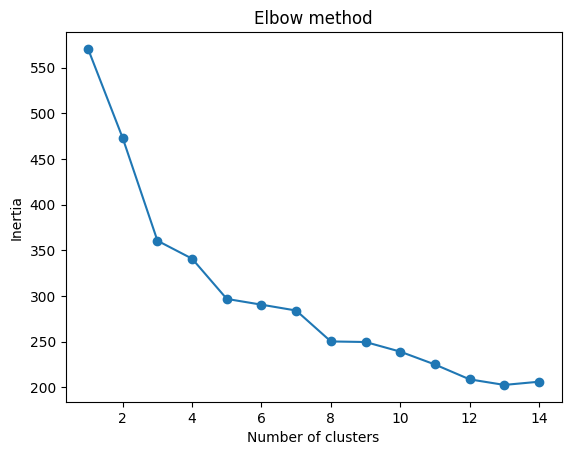

In [15]:
# Anzahl der Cluster, für die der Algorithmus ausgeführt werden soll
max_clusters = 15

# Leerer Datensatz, der die finalen Resultate enthalten wird
inertias = []

# Schleife: Für jeden Cluster-Wert i...
for i in range(1,max_clusters):
    # ...generiere ein leeres Modell unter der Annahme, dass es i Cluster enthält
    kmeans = KMeans(n_clusters = i, n_init = 'auto')
    # ...trainiere das Modell mit den Daten
    kmeans.fit(x)
    # ...füge die Kennzahl 'Inertia' in den finalen Datensatz ein
    inertias.append(kmeans.inertia_)

# Stelle das Resultat grafisch dar
plt.plot(range(1,max_clusters), inertias, marker='o')
plt.title('Elbow method')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()

Nachdem die Kurve ab dem 3. Punkt nicht mehr so schnell fällt wie zuvor, könnte man darauf schließen, dass der Datensatz drei wesentliche Cluster enthält.

## Hierarchical clustering

In [17]:
# Erstelle ein 'leeres' Modell
birch = Birch(n_clusters = 3)

# Trainiere das Modell
birch.fit(x_scaled)

Birch()

In [18]:
birch.predict(x)

array([0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 2, 1, 2, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 2])

## Exkurs B: Lassen sich regionale Cluster erkennen?

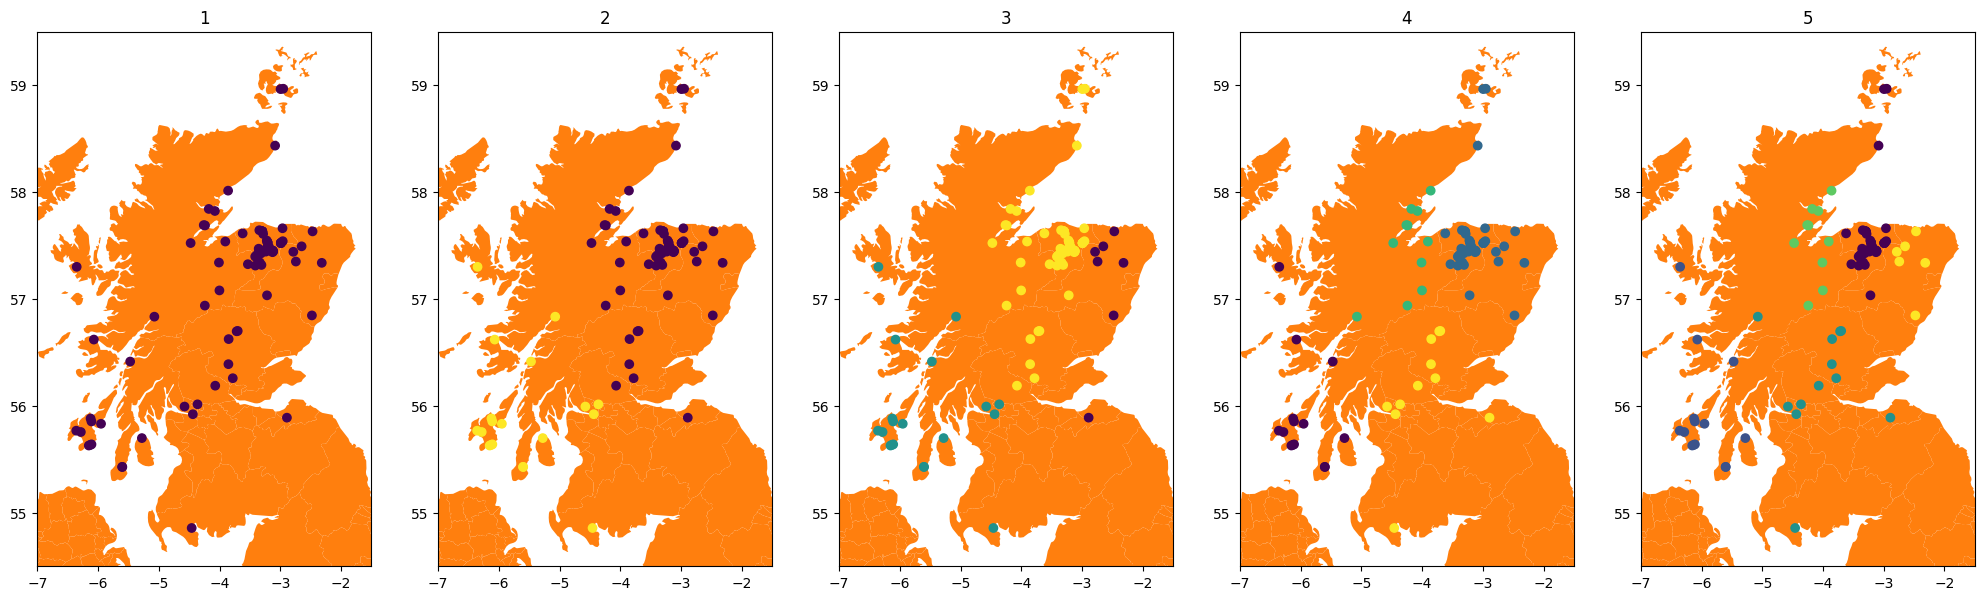

In [19]:
# Lösche Spalten, die nicht benötigt werden
#x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Latitude', 'Longitude'])
x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Fruity', 'Sweetness'])
x = x[["Longitude", "Latitude"]]

min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)
x_scaled = pd.DataFrame(x_scaled)
x_scaled.columns = x.columns


max_k = 5

fig, axes = plt.subplots(1, max_k, figsize = (25, 25))
axes = axes.flatten()

for i in range(1, max_k + 1):
    kmeans = KMeans(n_clusters = i, n_init = 'auto')
    kmeans.fit(x_scaled)
    pred = kmeans.predict(x_scaled)
    ctry.plot(ax = axes[i - 1], color = "tab:orange")
    axes[i - 1].axis([-7, -1.5, 54.5, 59.5]) # Durch Ausprobieren ermittelt
    axes[i - 1].scatter(x = coords_new[['Longitude']], y = coords_new[['Latitude']], marker='o', c = pred)
    axes[i - 1].set_title(i)

plt.show()

### Silhouette-Analyse

Die Silhouette-Analyse zeigt, wie gut jede Beobachtung zu ihrem Cluster passt. Der Code folgt einem Beispiel aus der Dokumentation von `scikit-learn` (siehe Quellen).

For n_clusters = 2 The average silhouette_score is : 0.6877368527491624
For n_clusters = 3 The average silhouette_score is : 0.5866407167419374
For n_clusters = 4 The average silhouette_score is : 0.5571456972448381
For n_clusters = 5 The average silhouette_score is : 0.5336587725126227
For n_clusters = 6 The average silhouette_score is : 0.5808401752655633


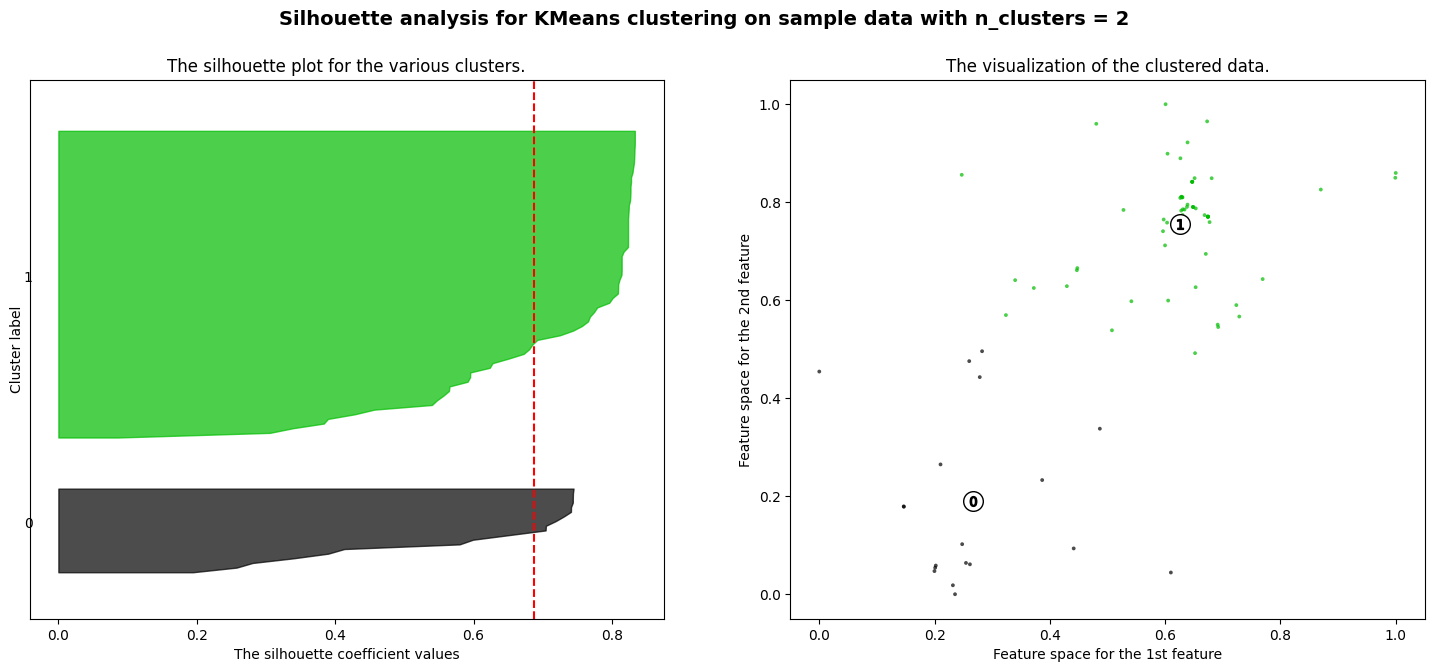

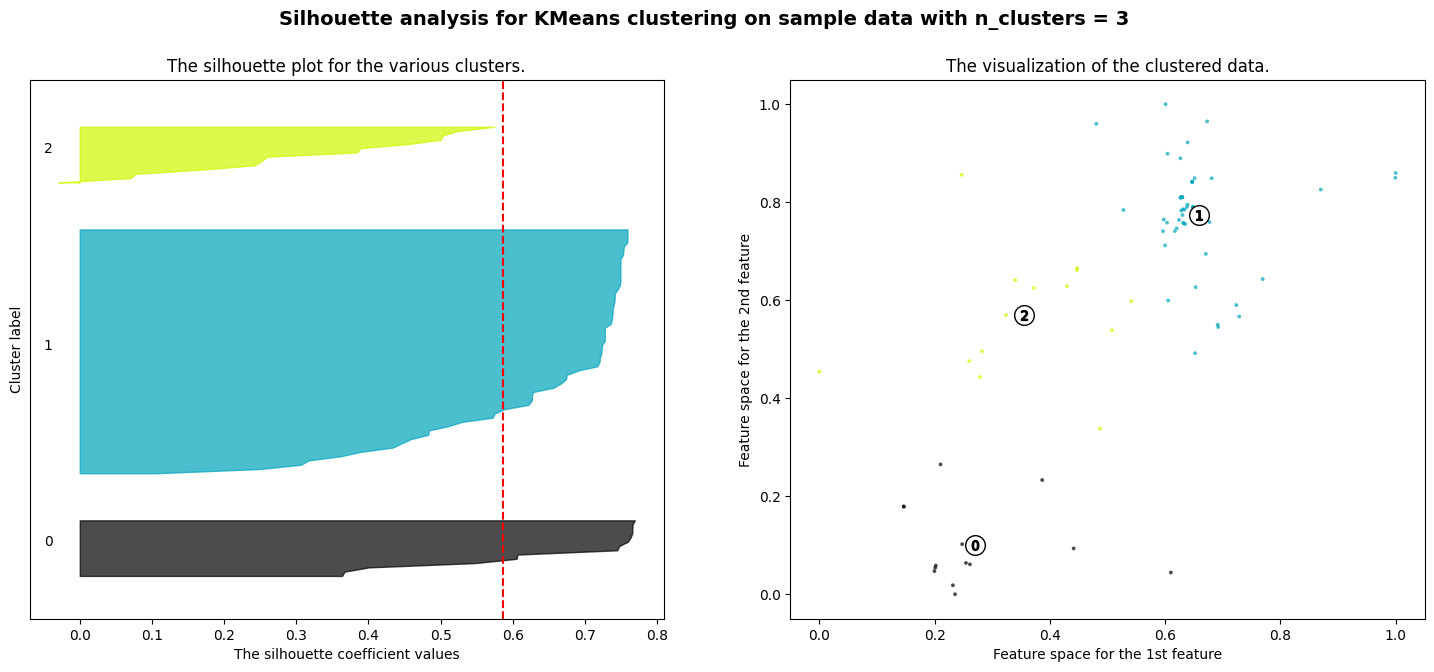

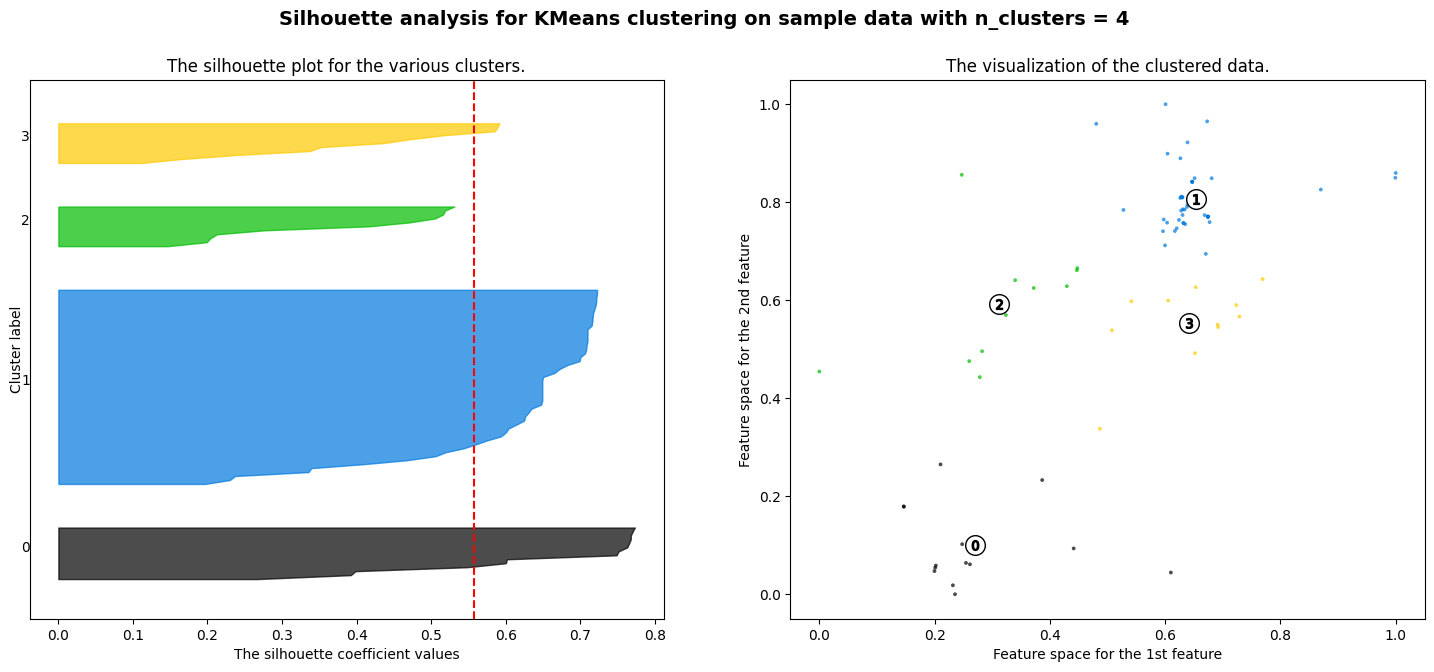

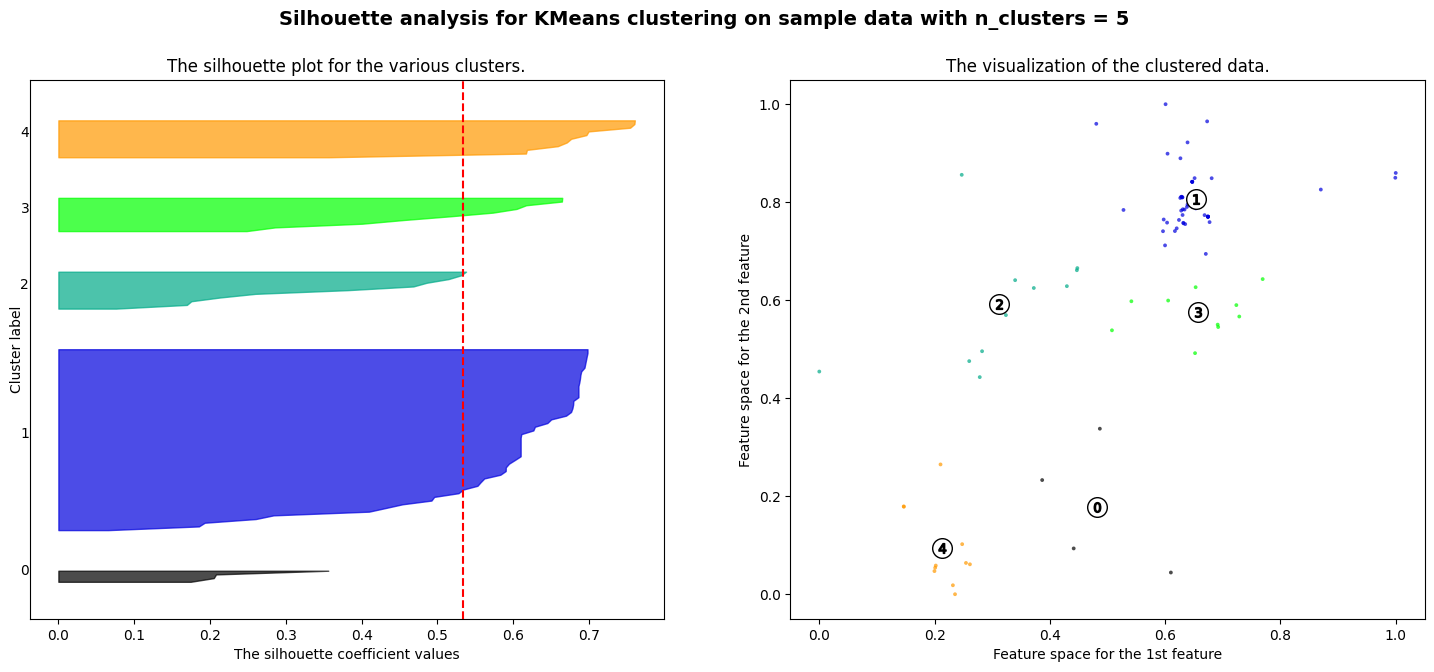

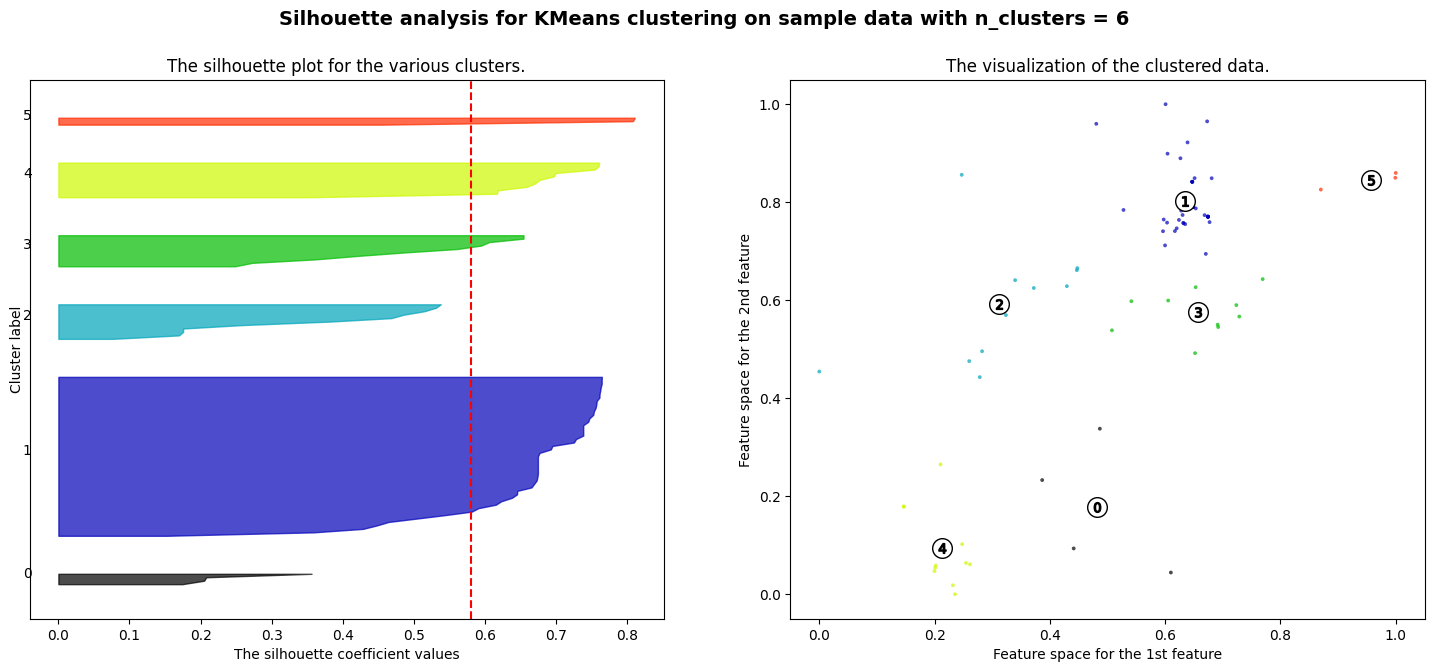

In [22]:
range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
    # Erstelle eine Grafik mit 1 Zeile und 2 Spalten
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # Die erste Grafik ist der Silhouette-Plot
    # Der Silhouette-Koeffizient liegt zwischen -1 und 1, in diesem Beispiel aber
    # immer innerhalb von [-0.1, 1]
    #ax1.set_xlim([-0.1, 1])
    # (n_clusters+1)*10 fügt Leerraum zwischen den Silhouette-Plots der
    # einzelnen Cluster ein, um sie klar voneinander abzugrenzen.
    ax1.set_ylim([0, len(x_scaled) + (n_clusters + 1) * 10])

    # Initialisiere das Modell mit n_clusters Clustern und dem Zufalls-Seed 10,
    # damit das Ergebnis reproduzierbar ist.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10, n_init = 'auto')
    cluster_labels = clusterer.fit_predict(x_scaled)

    # silhouette_score liefert den Durchschnitt über alle Beobachtungen.
    # Er zeigt, wie dicht und wie klar getrennt die gebildeten Cluster sind
    silhouette_avg = silhouette_score(x_scaled, cluster_labels)
    print(
        "For n_clusters =",
        n_clusters,
        "The average silhouette_score is :",
        silhouette_avg,
    )

    # Berechne den Silhouette-Wert jeder Beobachtung
    sample_silhouette_values = silhouette_samples(x_scaled, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Sammle die Silhouette-Werte der Beobachtungen in
        # Cluster i und sortiere sie
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Beschrifte die Silhouette-Plots in der Mitte mit der Nummer des Clusters
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Berechne y_lower für den nächsten Plot
        y_lower = y_upper + 10  # 10 Einheiten Abstand

    ax1.set_title("The silhouette plot for the various clusters.")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # Senkrechte Linie für den durchschnittlichen Silhouette-Score aller Werte
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Entferne die Beschriftung der y-Achse
    #ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # Die zweite Grafik zeigt die gebildeten Cluster
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        #x[:, 0], x[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
        x_scaled.iloc[:, 0], x_scaled.iloc[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )

    # Beschrifte die Cluster
    centers = clusterer.cluster_centers_
    # Zeichne weiße Kreise in die Clusterzentren
    ax2.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="o",
        c="white",
        alpha=1,
        s=200,
        edgecolor="k",
    )

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

    ax2.set_title("The visualization of the clustered data.")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(
        "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

In [23]:
x_scaled

,Longitude,Latitude
0,0.429495,0.628686
1,0.633648,0.785012
2,0.626505,0.889675
3,0.202110,0.058504
4,0.604132,0.899072
...,...,...
81,0.441341,0.093458
82,0.605209,0.599355
83,0.596264,0.740819
84,0.616923,0.741134


## Feature selection

In [24]:
x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Medicinal', 'Sweetness', 'Fruity'])#, 'Longitude', 'Latitude', 'Fruity', 'Sweetness'])
min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)
x_scaled = pd.DataFrame(x_scaled)
x_scaled = x_scaled.to_numpy()

result = []

for cluster_i in [2, 3, 4, 5, 6]:
    for model_i in range(10):
        kmeans = KMeans(n_clusters = cluster_i, n_init = 'auto')
        kmeans.fit(x_scaled)
        pred = kmeans.predict(x_scaled)
        temp = pred.copy()
        
        for i in range(0, cluster_i):
            position_pos = pred == i
            position_neg = pred != i
            temp[position_pos] = 1
            temp[position_neg] = 0
            inf = mutual_info_classif(x_scaled, temp, discrete_features = False)
            inf = pd.DataFrame([inf], columns = x.columns)
            inf['ncluster'] = cluster_i
            inf['group'] = i
            result.append(inf)

result = pd.concat(result).reset_index(drop = True)

result

,Body,Smoky,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral,Latitude,Longitude,ncluster,group
0,0.026749,0.071870,0.365357,0.003589,0.009093,0.075676,0.057869,0.000000,0.031775,0.000000,0.000000,2,0
1,0.000000,0.062160,0.365357,0.045264,0.026909,0.005465,0.000000,0.000000,0.038288,0.000000,0.000000,2,1
2,0.056199,0.116831,0.000000,0.088769,0.000000,0.008218,0.000000,0.084523,0.004993,0.389000,0.202984,2,0
3,0.015974,0.106244,0.012204,0.128167,0.000000,0.094771,0.000528,0.033691,0.020517,0.389000,0.202984,2,1
4,0.009879,0.029817,0.000000,0.091842,0.102475,0.177806,0.108417,0.000000,0.000000,0.130913,0.174252,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.000000,0.015356,0.000000,0.059203,0.029009,0.004275,0.003793,0.000000,0.027809,0.014748,0.035874,6,1
196,0.166090,0.097666,0.000000,0.061078,0.018653,0.152601,0.000000,0.081067,0.112957,0.178297,0.108152,6,2
197,0.175856,0.070391,0.000000,0.000000,0.094320,0.279250,0.000000,0.144617,0.010212,0.176482,0.096110,6,3
198,0.038045,0.106164,0.098635,0.068223,0.000000,0.002366,0.000000,0.041366,0.061624,0.004934,0.000000,6,4


In [25]:
result.describe()

,Body,Smoky,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral,Latitude,Longitude,ncluster,group
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,0.104018,0.081876,0.119191,0.050473,0.062093,0.101594,0.032508,0.049159,0.034061,0.092104,0.062926,4.500000,1.750000
std,0.089809,0.067176,0.129929,0.050733,0.076201,0.102638,0.053462,0.063188,0.041350,0.095819,0.059331,1.326195,1.482731
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
25%,0.020579,0.029358,0.012844,0.000000,0.000000,0.006383,0.000000,0.000000,0.000000,0.018502,0.002338,3.750000,0.750000
50%,0.096225,0.072534,0.064798,0.042137,0.032568,0.063767,0.007783,0.021840,0.016270,0.070187,0.057247,5.000000,1.500000
75%,0.171036,0.112193,0.198058,0.081149,0.096817,0.182720,0.039436,0.068646,0.050321,0.138936,0.088239,6.000000,3.000000
max,0.343622,0.286546,0.365357,0.212127,0.438889,0.349305,0.258281,0.261618,0.155678,0.469258,0.302024,6.000000,5.000000


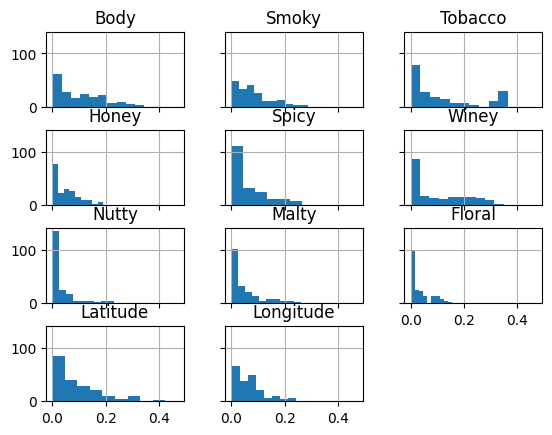

In [26]:
result.drop(["ncluster", "group"], axis = 1).hist(sharex = True, sharey = True);

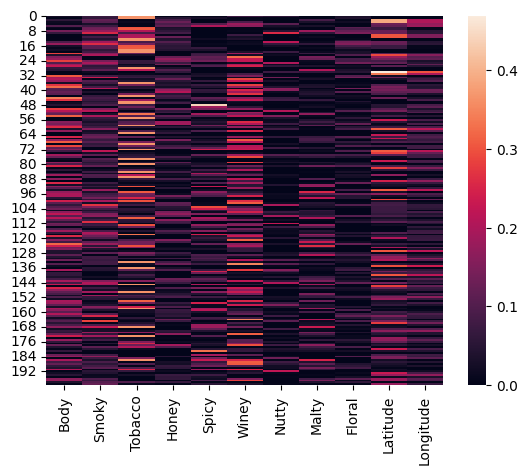

In [27]:
sns.heatmap(result.drop(["ncluster","group"], axis = 1));

## Quellen

* https://www.kaggle.com/datasets/koki25ando/scotch-whisky-dataset
* https://simplemaps.com/gis/country/gb
* https://geopandas.org/
* https://scikit-learn.org/stable/modules/clustering.html
* https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html
* https://www.w3schools.com/python/python_ml_k-means.asp